In [1]:
import pandas as pd
import matplotlib.pyplot as plt

both = pd.read_csv("../data/clean/ni_ie_inactivity_2009_2025.csv")
print(both.head())

   year  inactivity_ni  inactivity_ie    gap
0  2009           30.1         26.975  3.125
1  2010           29.1         28.450  0.650
2  2011           27.6         28.825 -1.225
3  2012           27.6         28.875 -1.275
4  2013           27.5         28.225 -0.725


In [3]:
share_15 = 0.02
inactive_15 = 95

both["inactivity_ie_adj"] = (both["inactivity_ie"] - share_15 * inactive_15) / (1 - share_15)
print(both.round(1))

    year  inactivity_ni  inactivity_ie  gap  inactivity_ie_adj
0   2009           30.1           27.0  3.1               25.6
1   2010           29.1           28.4  0.6               27.1
2   2011           27.6           28.8 -1.2               27.5
3   2012           27.6           28.9 -1.3               27.5
4   2013           27.5           28.2 -0.7               26.9
5   2014           27.6           28.2 -0.6               26.8
6   2015           27.1           28.0 -0.9               26.6
7   2016           26.0           27.4 -1.4               26.0
8   2017           27.6           27.4  0.2               26.0
9   2018           27.2           27.2 -0.0               25.8
10  2019           26.2           26.8 -0.6               25.5
11  2020           28.0           29.2 -1.2               27.9
12  2021           27.0           25.5  1.5               24.1
13  2022           26.3           23.2  3.0               21.8
14  2023           24.7           22.5  2.2            

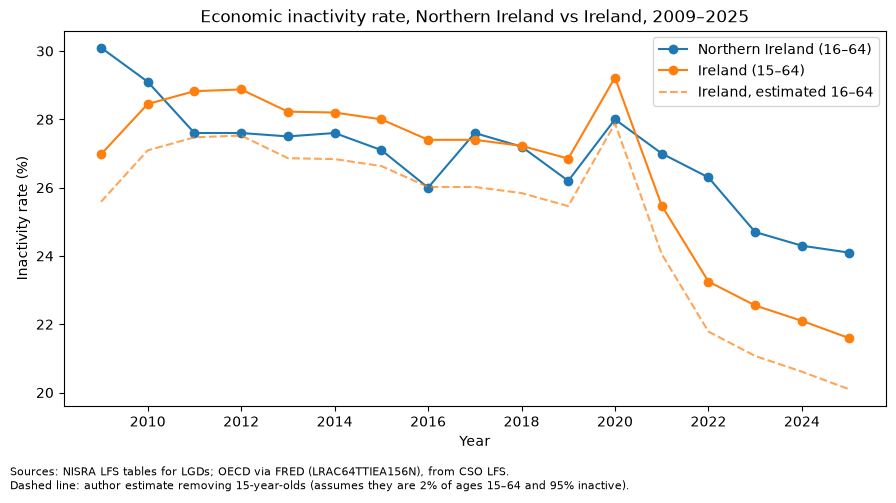

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(both["year"], both["inactivity_ni"], marker="o", color="C0", label="Northern Ireland (16–64)")
ax.plot(both["year"], both["inactivity_ie"], marker="o", color="C1", label="Ireland (15–64)")
ax.plot(both["year"], both["inactivity_ie_adj"], linestyle="--", color="C1", alpha=0.7, label="Ireland, estimated 16–64")

ax.set_title("Economic inactivity rate, Northern Ireland vs Ireland, 2009–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Inactivity rate (%)")
ax.legend()

fig.text(0.01, 0.01, "Sources: NISRA LFS tables for LGDs; OECD via FRED (LRAC64TTIEA156N), from CSO LFS.\nDashed line: author estimate removing 15-year-olds (assumes they are 2% of ages 15–64 and 95% inactive).", fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 1))

fig.savefig("../charts/chart1_ni_vs_ireland.png", dpi=150)
plt.show()